In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

# Configuramos el estilo de las gráficas para que se vean profesionales en clase
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. CARGA DE DATOS ( CALIFORNIA HOUSING DATASET )
# DESCARGAMOS EL DATASET DE VIVIENDAS DE CALIFORNIA (REGRESIÓN)
# as_frame=True lo entrega como tabla de pandas, para pedir columnas por nombre
california = fetch_california_housing(as_frame=True)

# X: INGRESO MEDIO DE LOS HOGARES (MedInc), en decenas de miles de dólares (5.0 = $50,000)
# ES EL DATO QUE "CONOCEMOS" Y QUE USAREMOS PARA PREDECIR EL PRECIO DE LA VIVIENDA
# .values LO CONVIERTE A UN ARREGLO DE NUMPY Y [:50] TOMA SOLO LOS PRIMEROS 50 REGISTROS PARA SIMPLIFICAR EL EJEMPLO
X=california.data['MedInc'].values[:50] #tomamos un subconjunto pequeño para simplificar el ejemplo

# Y: VALOR MEDIO DE LAS CASAS DE LA ZONA, EN CIENTOS DE MILES DE DÓLARES (2.0 = $200,000)
# ES LO QUE QUEREMOS PREDECIR, EL PRECIO DE LA VIVIENDA
Y=california.target.values[:50]


print(f"Datos cargados con éxito: {len(X)} Registros analizados.")

Datos cargados con éxito: 50 Registros analizados.


In [4]:
# 2. INICIALIZACIÓN DE PARÁMETROS
w = 0.0 # PENDIENTE: CUANTO SUBE EL VALOR DE LA CASA POR CADA UNIDAD DE INGRESO
b = 0.0 #ORDENADA: VALOR DE LA CASA CUANDO EL INGRESO ES CERO

# Hiperparámetros
learning_rate = 0.005 # Tasa de aprendizaje ajustada para esta escala
epochs = 1500         # Iteraciones de entrenamiento
n = len(X)

# Historial para graficar la evolución del costo si lo deseas mostrar
historial_costos = []

# 3. ENTRENAMIENTO
for epoch in range(epochs):
    # Predicción actual
    Y_pred = w * X + b
    
    # Cálculo del Costo (MSE)
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)
    
    # Derivadas parciales (Gradientes): INDICAN HACIA DONDE MOVER w Y b PARA QUE EL COSTO BAJE
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)
    
    # Actualización de pesos: DAMOS UN PASO (learning_rate) EN DIRECCIÓN CONTRARIA AL GRADIENTE
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Entrenamiento completado!")
print(f"Ecuación final aprendida: Valor de la casa = {w:.4f} * (Ingreso medio) + {b:.4f}")

¡Entrenamiento completado!
Ecuación final aprendida: Valor de la casa = 0.4449 * (Ingreso medio) + 0.5895


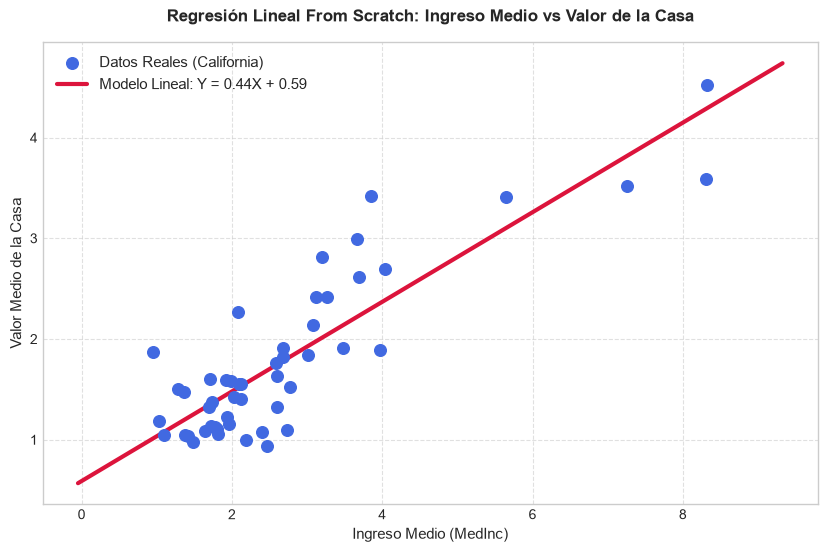

In [5]:
# 4. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(10, 6))

# Dibujar los puntos reales (ZONAS DE CALIFORNIA)
plt.scatter(X, Y, color='royalblue', s=70, label='Datos Reales (California)', zorder=5)

# Dibujar la línea de tendencia aprendida por el modelo
X_linea = np.linspace(min(X) - 1, max(X) + 1, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Etiquetas y formato estético
plt.title('Regresión Lineal From Scratch: Ingreso Medio vs Valor de la Casa', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingreso Medio (MedInc)', fontsize=11)
plt.ylabel('Valor Medio de la Casa', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

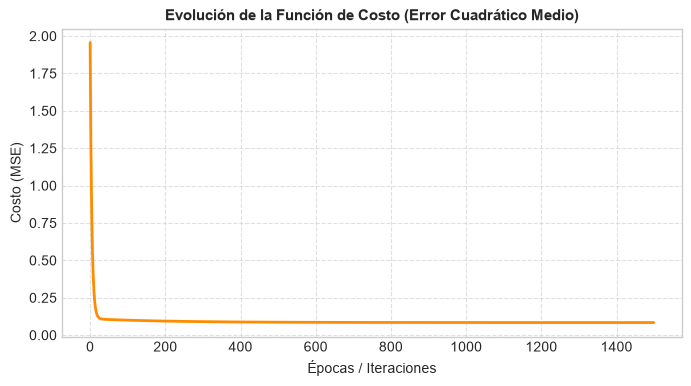

In [6]:
# SI LA CURVA BAJA Y SE APLANA AL FINAL, EL MODELO TERMINO DE APRENDER
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución de la Función de Costo (Error Cuadrático Medio)', fontsize=11, fontweight='bold')
plt.xlabel('Épocas / Iteraciones', fontsize=10)
plt.ylabel('Costo (MSE)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()